# Model 6: Hybrid Splines + Random Forest Architecture

This notebook implements a novel two-stage hybrid quantitative architecture: a natural cubic B-spline baseline captures the interpretable macroeconomic surface structure, while a Random Forest regressor is fitted to the spline residuals to eliminate local microstructure pricing anomalies.

**Author:** Sérgio da Cunha Sobral
**Degree:** Master in Financial Mathematics (ISCTE-IUL)
**Supervisor:** Prof.ª Doutora Diana Mendes


### 1. Library Imports


In [1]:
import os
import json
import joblib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score
from typing import Optional, Sequence, Iterable, Tuple
from sklearn.base import BaseEstimator, TransformerMixin

from __future__ import annotations

from sklearn.ensemble import RandomForestRegressor

### 2. Core Paths & Configuration


In [2]:
# Designações Centrais e Caminhos
DIR_TRATADOS = "02_data/processed/"
DIR_RESULTADOS = "04_outputs/03_models_metadata/06_model_hybrid_random_forest/"
DIR_GRAFICOS = "04_outputs/01_figures/09_model_hybrid_random_forest/"
DIR_TABELAS = "04_outputs/02_tables/06_model_hybrid_random_forest/"
DIR_RESULTADOS_SPLINES = "04. Resultados/03. Modelo #3 - Splines/"

# Criar diretório de gráficos/tabelas/resultados se não existir
os.makedirs(DIR_GRAFICOS, exist_ok=True)
os.makedirs(DIR_RESULTADOS, exist_ok=True)
os.makedirs(DIR_TABELAS, exist_ok=True)

# Input data splits
ficheiro_universo        = os.path.join(DIR_TRATADOS, "Universo_Modelizacao_v1.00.parquet")
ficheiro_inner_train     = os.path.join(DIR_TRATADOS, "df_inner_train.parquet")
ficheiro_inner_tunning   = os.path.join(DIR_TRATADOS, "df_inner_tunning.parquet")
ficheiro_train_full      = os.path.join(DIR_TRATADOS, "df_train_full.parquet")
ficheiro_test_puro       = os.path.join(DIR_TRATADOS, "df_test_puro.parquet")

# Caminhos do modelo Splines (para carregar previsões base)
SPLINES_MODEL_PATH_FINAL = os.path.join(DIR_RESULTADOS_SPLINES, "03. Splines_model.joblib")
SPLINES_META_PATH_FINAL  = os.path.join(DIR_RESULTADOS_SPLINES, "03. Splines_model.meta.json")

# Model and metadata paths (nomes finais)
MODEL_PATH_INNER = os.path.join(DIR_RESULTADOS, "06. Híbrido_RF_model_inner.joblib")
META_PATH_INNER  = os.path.join(DIR_RESULTADOS, "06. Híbrido_RF_model_inner.meta.json")

BEST_PARAMS = os.path.join(DIR_RESULTADOS, "06. Híbrido_RF_best_params.json")
LINEAR_ADJUST = os.path.join(DIR_RESULTADOS, "06. Híbrido_RF_linear_adjust.json")

MODEL_PATH_FINAL = os.path.join(DIR_RESULTADOS, "06. Híbrido_RF_model.joblib")
META_PATH_FINAL  = os.path.join(DIR_RESULTADOS, "06. Híbrido_RF_model.meta.json")

### 3. Load Auxiliary Utilities


Palete de Cores:
azul1: #11469b
azul2: #2063c0
azul3: #5a90e7
cinza1: #777777
cinza2: #AAAAAA
cinza3: #bbbbbb
preto: #000000
branco: #ffffff

Estilos de Linha:
contínua: -
tracejada: --
ponto-traço: -.
pontilhada: :
contínua2: -
tracejada2: --
ponto-traço2: -.
pontilhada2: :


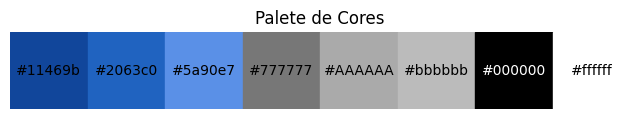

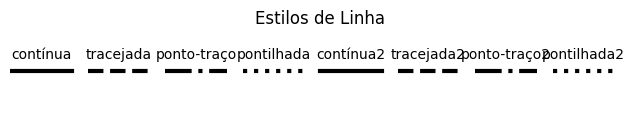

In [3]:
%run "03_notebooks/00_utils/01_auxiliary_functions.ipynb"

# Visualizar paleta de cores e estilos de linha carregados
if 'mostrar_cores' in globals() and 'PALETA_CORES' in globals():
    mostrar_cores(PALETA_CORES)
if 'mostrar_estilos' in globals() and 'ESTILOS_LINHA' in globals():
    mostrar_estilos(ESTILOS_LINHA)

### 4. Data Ingestion (Train, Tuning, and Test Splits)


In [4]:
# Carregamento do ficheiro parquet
df_inner_train = pd.read_parquet(ficheiro_inner_train)
df_inner_tunning = pd.read_parquet(ficheiro_inner_tunning)
df_train_full = pd.read_parquet(ficheiro_train_full)
df_test_puro = pd.read_parquet(ficheiro_test_puro)

# Verificação inicial
(df_inner_train.shape, df_inner_tunning.shape, df_train_full.shape, df_test_puro.shape)

((5970843, 11), (1534395, 11), (7505238, 11), (1292514, 11))

### 5. Baseline Spline Model Pre-estimation


In [5]:
# Definição necessária para carregar o modelo Splines treinado
# (classe usada no pickle do pipeline)
class TensorBSplineFeatures(BaseEstimator, TransformerMixin):
    """
    Gera features por produto-tensor de B-splines em duas dimensões (m, T).

    Parâmetros principais:
      n_knots_m, n_knots_t : nº de nós por dimensão
      degree               : grau do B-spline (3 = cúbico)
      include_bias         : inclui termo de bias das bases
      knots_mode           : 'quantile' (preferido) ou 'uniform' (fallback)
      extrapolation        : 'linear' recomendado
      with_scaler          : standardizar inputs antes das bases
    """
    def __init__(
        self,
        n_knots_m: int = 8,
        n_knots_t: int = 6,
        degree: int = 3,
        include_bias: bool = False,
        knots_mode: str = "quantile",
        extrapolation: str = "linear",
        with_scaler: bool = True,
    ):
        self.n_knots_m = n_knots_m
        self.n_knots_t = n_knots_t
        self.degree = degree
        self.include_bias = include_bias
        self.knots_mode = knots_mode
        self.extrapolation = extrapolation
        self.with_scaler = with_scaler

        self.scaler_m_: Optional[StandardScaler] = None
        self.scaler_t_: Optional[StandardScaler] = None
        self.spline_m_: Optional[SplineTransformer] = None
        self.spline_t_: Optional[SplineTransformer] = None
        self.knots_mode_m_: Optional[str] = None
        self.knots_mode_t_: Optional[str] = None
        self.n_out_m_: Optional[int] = None
        self.n_out_t_: Optional[int] = None

    def _fit_single(self, x: np.ndarray, n_knots: int, label: str) -> Tuple[Optional[StandardScaler], SplineTransformer, str, int]:
        scaler = None
        x_fit = x
        if self.with_scaler:
            scaler = StandardScaler()
            x_fit = scaler.fit_transform(x)

        knots_mode_used = self.knots_mode
        try:
            spline = SplineTransformer(
                n_knots=n_knots,
                degree=self.degree,
                include_bias=self.include_bias,
                extrapolation=self.extrapolation,
                knots=self.knots_mode,
            )
            B = spline.fit_transform(x_fit)
        except TypeError:
            knots_mode_used = "uniform"
            spline = SplineTransformer(
                n_knots=n_knots,
                degree=self.degree,
                include_bias=self.include_bias,
                extrapolation=self.extrapolation,
            )
            B = spline.fit_transform(x_fit)

        n_out = B.shape[1]
        return scaler, spline, knots_mode_used, n_out

    def fit(self, X: np.ndarray, y: Optional[np.ndarray] = None):
        X = np.asarray(X)
        if X.ndim != 2 or X.shape[1] != 2:
            raise ValueError("TensorBSplineFeatures espera X com shape (n_amostras, 2): colunas [m, T].")

        m = X[:, [0]]
        t = X[:, [1]]

        self.scaler_m_, self.spline_m_, self.knots_mode_m_, self.n_out_m_ = self._fit_single(m, self.n_knots_m, "m")
        self.scaler_t_, self.spline_t_, self.knots_mode_t_, self.n_out_t_ = self._fit_single(t, self.n_knots_t, "t")
        return self

    def transform(self, X: np.ndarray) -> np.ndarray:
        if any(obj is None for obj in [self.spline_m_, self.spline_t_]):
            raise RuntimeError("Transformer não foi ajustado. Chama .fit primeiro.")

        m = X[:, [0]]
        t = X[:, [1]]

        if self.with_scaler:
            m = self.scaler_m_.transform(m)
            t = self.scaler_t_.transform(t)

        Bm = self.spline_m_.transform(m)
        Bt = self.spline_t_.transform(t)

        Xs = np.einsum('ij,ik->ijk', Bm, Bt).reshape(Bm.shape[0], -1)
        return Xs

# --- Helpers para carregar e aplicar o modelo Splines ---

def load_splines(model_path: str = SPLINES_MODEL_PATH_FINAL, meta_path: str = SPLINES_META_PATH_FINAL):
    model = joblib.load(model_path)
    meta = None
    if os.path.exists(meta_path):
        with open(meta_path, "r", encoding="utf-8") as f:
            meta = json.load(f)
    return model, meta


def apply_splines(df: pd.DataFrame, model, features=("log_moneyness", "T"), pred_col="ivs_splines"):
    cols = list(features)
    faltam = [c for c in cols if c not in df.columns]
    if faltam:
        raise ValueError(f"Colunas em falta para Splines: {faltam}")
    X = df[cols].to_numpy(dtype=float)
    y_hat = model.predict(X).astype("float32")
    out = df.copy()
    out[pred_col] = y_hat
    return out

# === SPLINES: carregar modelo e gerar ivs_splines + residuo (inner sets) ===

# 1) Carregar Splines final
splines_model, splines_meta = load_splines(SPLINES_MODEL_PATH_FINAL, SPLINES_META_PATH_FINAL)
print("[Splines] Modelo carregado.")

# 2) Aplicar em inner_train e inner_tunning
_df_in_spl  = apply_splines(df_inner_train,   splines_model, features=("log_moneyness", "T"), pred_col="ivs_splines")
_df_va_spl  = apply_splines(df_inner_tunning, splines_model, features=("log_moneyness", "T"), pred_col="ivs_splines")
_df_trfull_spl = apply_splines(df_train_full, splines_model, features=("log_moneyness", "T"), pred_col="ivs_splines")
_df_test_spl   = apply_splines(df_test_puro,  splines_model, features=("log_moneyness", "T"), pred_col="ivs_splines")

# 3) Calcular resíduos (modelo − teórico)
_df_in_spl["residuo"] = _df_in_spl["iv_teorica"].astype("float32") - _df_in_spl["ivs_splines"].astype("float32")
_df_va_spl["residuo"] = _df_va_spl["iv_teorica"].astype("float32") - _df_va_spl["ivs_splines"].astype("float32")
_df_trfull_spl["residuo"] = _df_trfull_spl["iv_teorica"].astype("float32") - _df_trfull_spl["ivs_splines"].astype("float32")
_df_test_spl["residuo"] = _df_test_spl["iv_teorica"].astype("float32") - _df_test_spl["ivs_splines"].astype("float32")

# 4) Guardar cópias de trabalho
df_inner_train = _df_in_spl
df_inner_tunning = _df_va_spl
df_train_full = _df_trfull_spl
df_test_puro = _df_test_spl

print("✔️ ivs_splines e residuo calculados.")
display(df_inner_train[["ivs_splines","iv_teorica","residuo"]].sample(20))

[Splines] Modelo carregado.
✔️ ivs_splines e residuo calculados.


,ivs_splines,iv_teorica,residuo
4617263,0.117920,0.093800,-0.024120
3470579,0.149335,0.196848,0.047513
2440818,0.132020,0.166950,0.034931
3952146,0.154524,0.154517,-0.000006
1570766,0.134227,0.151235,0.017007
2060982,0.429985,0.414568,-0.015417
3719084,0.123085,0.156892,0.033807
1394491,0.377231,0.385336,0.008105
2310600,0.114948,0.110201,-0.004748
1487985,0.182738,0.195623,0.012885


### 5. Modeling Setup & Pre-estimation Checks


In [6]:
# 0) Config
FEATURES = ("log_moneyness", "T", "option_is_call")
TARGET   = "residuo"
PRED_COL = "residuo_modelo"

# 1) Checks básicos
def _basic_checks(df, features, target):
    cols = list(features) + [target]
    em_falta = [c for c in cols if c not in df.columns]
    if em_falta: raise ValueError(f"Colunas em falta: {em_falta}")

    sub = df[cols]
    nan_counts = sub.isna().sum()
    if nan_counts.any():
        raise ValueError(f"Há NaN nas colunas usadas: {nan_counts[nan_counts>0].to_dict()}")

    inf_detalhe = {}
    for c in cols:
        v = sub[c].to_numpy()
        if not np.isfinite(v).all():
            inf_detalhe[c] = int(np.isinf(v).sum()) + int(np.isnan(v).sum())
    if inf_detalhe:
        raise ValueError(f"Valores não finitos detectados: {inf_detalhe}")
    return sub



# ---------------------------------------------------------------------
# 2) Utilidades de dtype e sampling (RAM‑safe)
def _prepare_xy(df: pd.DataFrame, features: Iterable[str], target: str):
    # Cast eficiente para poupar RAM
    df2 = df.copy()
    for c in features:
        if c == "option_is_call":
            df2[c] = df2[c].astype("int8")
        else:
            df2[c] = df2[c].astype("float32")

    X = df2[list(features)].values 
    y = df2[target].astype("float32")  
    return X, y

def _make_bins(df: pd.DataFrame, lm_col="log_moneyness", t_col="T", n_lm=30, n_t=12):
    lm_bins = np.linspace(df[lm_col].min(), df[lm_col].max(), n_lm+1)
    t_bins  = np.linspace(df[t_col].min(),  df[t_col].max(),  n_t+1)
    return lm_bins, t_bins

def balanced_sample(df, max_per_bin=5000, lm_col="log_moneyness", t_col="T"):
    df = df.copy()
    lm_q = np.quantile(df[lm_col].values, np.linspace(0, 1, 31))
    t_q  = np.quantile(df[t_col].values,  np.linspace(0, 1, 13))
    lm_edges = np.unique(lm_q)
    t_edges  = np.unique(t_q)
    if lm_edges.size < 3:
        lm_edges = np.linspace(df[lm_col].min(), df[lm_col].max(), 31)
    if t_edges.size < 3:
        t_edges  = np.linspace(df[t_col].min(),  df[t_col].max(),  13)

    lm_cat = pd.cut(df[lm_col], bins=lm_edges, include_lowest=True, right=False)
    t_cat  = pd.cut(df[t_col],  bins=t_edges,  include_lowest=True, right=False)
    df["_lm_bin"] = lm_cat.cat.codes
    df["_t_bin"]  = t_cat.cat.codes

    out = (df.loc[(df["_lm_bin"]>=0) & (df["_t_bin"]>=0)]
             .groupby(["_lm_bin","_t_bin"], group_keys=False)
             .apply(lambda g: g.sample(min(len(g), max_per_bin), random_state=42))
             .drop(columns=["_lm_bin","_t_bin"]))
    return out



# ---------------------------------------------------------------------
# 3) Construção do modelo

from sklearn.ensemble import RandomForestRegressor

def build_rf(params: dict | None = None) -> RandomForestRegressor:
    base = dict(
        n_estimators=600,
        max_depth=14,
        min_samples_leaf=100,
        min_samples_split=300,
        max_features='sqrt',
        bootstrap=True,
        max_samples=0.8,
        n_jobs=-1,
        random_state=42,
        oob_score=False,   # podes ativar se quiseres diagnóstico interno
    )
    if params: base.update(params)
    return RandomForestRegressor(**base)


# ---------------------------------------------------------------------
# 4) Tuning do modelo

def tune_rf(
    df_inner_train: pd.DataFrame,
    df_inner_tunning: pd.DataFrame,
    features: Iterable[str],
    target: str,
    n_iter: int = 24,
    use_balanced_sample: bool = True,
    max_per_bin: int = 5000,
    random_state: int = 42,
) -> dict:
    _basic_checks(df_inner_train, features, target)
    _basic_checks(df_inner_tunning, features, target)

    train_df = balanced_sample(df_inner_train, max_per_bin=max_per_bin) if use_balanced_sample else df_inner_train

    X_tr_s, y_tr_s = _prepare_xy(train_df, features, target)
    X_in,  y_in    = _prepare_xy(df_inner_train,   features, target)
    X_va,  y_va    = _prepare_xy(df_inner_tunning, features, target)

    rf = build_rf({"n_jobs": 1})  # evitar paralelismo aninhado
    param_dist = {
        # # Run 1
        # "n_estimators":      [500, 600],
        # "max_depth":         [14, 16],
        # "min_samples_leaf":  [50, 100],
        # "min_samples_split": [200, 300, 400],
        # "max_features":      [0.8, 1.0],
        # "max_samples":       [0.6, 0.8],
        # "bootstrap":         [True],

        # # Run 2
        # "n_estimators":      [600, 800, 1000],
        # "max_depth":         [12, 14, 16],
        # "min_samples_leaf":  [30, 50, 100],
        # "min_samples_split": [150, 300, 450],
        # "max_features":      ["sqrt", 0.8, 1.0],
        # "max_samples":       [0.6, 0.8, 0.9],
        # "bootstrap":         [True],

        # Run 3
        "n_estimators":      [800, 1000, 1200],
        "max_depth":         [12, 14, 16],
        "min_samples_leaf":  [30, 50, 100],
        "min_samples_split": [100, 150, 300],
        "max_features":      ["sqrt", 0.8],
        "max_samples":       [0.6, 0.8, 0.9],
        "bootstrap":         [True],
        # novos (opcional, pode usar só o primeiro):
        # "criterion":         ["squared_error"],
        # "ccp_alpha":         [0.0, 1e-5, 1e-4],

    }

    from sklearn.model_selection import RandomizedSearchCV
    rs = RandomizedSearchCV(
        rf, param_distributions=param_dist, n_iter=n_iter,
        scoring="neg_root_mean_squared_error", cv=2, n_jobs=-1,
        random_state=random_state, verbose=1, refit=False, return_train_score=False,
        error_score="raise",
    )
    rs.fit(X_tr_s, y_tr_s)
    best_params = dict(rs.best_params_)

    # Refit no inner_train completo com os melhores parâmetros
    rf_refit = build_rf({**best_params, "n_jobs": -1})
    rf_refit.fit(X_in, y_in)

    # # Previsões (clip só nas PREVISÕES)
    # y_hat_in = np.clip(rf_refit.predict(X_in).astype("float32"), 1e-4, 2.0)
    # y_hat_va = np.clip(rf_refit.predict(X_va).astype("float32"), 1e-4, 2.0)
    y_hat_in = rf_refit.predict(X_in).astype("float32")      # sem clip
    y_hat_va = rf_refit.predict(X_va).astype("float32")      # sem clip


    df_inner_train_pred   = df_inner_train.copy()
    df_inner_tunning_pred = df_inner_tunning.copy()
    df_inner_train_pred[PRED_COL]   = y_hat_in
    df_inner_tunning_pred[PRED_COL] = y_hat_va

    return best_params, df_inner_train_pred, df_inner_tunning_pred



# ---------------------------------------------------------------------
# 5) Treinar modelo final
from datetime import datetime, timezone

def train_rf(
    df_train_full: pd.DataFrame,
    features: Iterable[str],
    target: str,
    best_params: dict | None = None,
    oob_score: bool = False,
    return_in_sample_pred: bool = True,
    pred_col: str = PRED_COL
) -> tuple[RandomForestRegressor, dict, pd.DataFrame | None]:
    _basic_checks(df_train_full, features, target)
    X_tr, y_tr = _prepare_xy(df_train_full, features, target)

    params = dict(best_params) if best_params else {}
    if oob_score:
        params["oob_score"] = True
        params["bootstrap"] = True
        params.setdefault("max_samples", 0.8)

    rf = build_rf(params)
    rf.fit(X_tr, y_tr)

    meta = {
        "model_type": "RandomForestRegressor",
        "features": list(features),
        "target": target,
        "n_obs": int(X_tr.shape[0]),
        "params": rf.get_params(),
        "oob_score": float(getattr(rf, "oob_score_", np.nan)) if oob_score else None,
        "trained_at": datetime.now(timezone.utc).isoformat() + "Z",
        "date_min": str(df_train_full["quote_date"].min()) if "quote_date" in df_train_full.columns else None,
        "date_max": str(df_train_full["quote_date"].max()) if "quote_date" in df_train_full.columns else None,
    }

    df_train_pred = None
    if return_in_sample_pred:
        y_hat_tr = rf.predict(X_tr).astype("float32")
        # y_hat_tr = np.clip(y_hat_tr, 1e-4, 2.0)
        df_train_pred = df_train_full.copy()
        df_train_pred[pred_col] = y_hat_tr

    return rf, meta, df_train_pred


# ---------------------------------------------------------------------
# 6) Aplicar modelo RF
def apply_model(df, model, features, pred_col=PRED_COL, clip_pred=False):
    # só verifica features
    cols = list(features)
    faltam = [c for c in cols if c not in df.columns]
    if faltam: raise ValueError(f"Colunas em falta: {faltam}")

    X, _ = _prepare_xy(df.assign(__y=0.0), features, "__y")
    y_hat = model.predict(X).astype("float32")
    if clip_pred: y_hat = np.clip(y_hat, -2.0, 2.0)
    out = df.copy()
    out[pred_col] = y_hat
    return out


# ---------------------------------------------------------------------
# 6) Importâncias das features
from sklearn.inspection import permutation_importance

def rf_importances(
    model: RandomForestRegressor,
    df_ref: pd.DataFrame,
    features: Iterable[str],
    target: str,
    n_repeats: int = 5,
) -> pd.DataFrame:
    """Devolve DataFrame com importâncias impurity e por permutação (ordenado por permutação)."""
    # impurity-based
    imp_impurity = getattr(model, "feature_importances_", None)
    df_imp = pd.DataFrame({"feature": list(features), "impurity_importance": imp_impurity})

    # permutation (mais robusta)
    X_ref, y_ref = _prepare_xy(df_ref, features, target)
    perm = permutation_importance(model, X_ref, y_ref, n_repeats=n_repeats, random_state=42, n_jobs=-1)
    df_imp["permutation_importance"] = perm.importances_mean
    df_imp["permutation_std"] = perm.importances_std

    return df_imp.sort_values("permutation_importance", ascending=False).reset_index(drop=True)


# ---------------------------------------------------------------------
# 7) Guardar / carregar modelo
def save_model(model, meta: dict, model_path: str, meta_path: str):
    """Guarda o pipeline treinado (joblib) e o dicionário meta (JSON) nos caminhos indicados."""
    joblib.dump(model, model_path)
    with open(meta_path, "w", encoding="utf-8") as f:
        json.dump(meta, f, ensure_ascii=False, indent=2)

def load_model(model_path: str, meta_path: str):
    """Carrega o pipeline treinado e o meta JSON a partir dos caminhos indicados; devolve (model, meta)."""
    model = joblib.load(model_path)
    meta = None
    if os.path.exists(meta_path):
        with open(meta_path, "r", encoding="utf-8") as f:
            meta = json.load(f)
    return model, meta

### 7. Hyperparameter Tuning & Validation (inner_tunning)


In [7]:
# TUNING
RF_BEST_PARAMS, df_inner_train_pred, df_inner_tunning_pred = tune_rf(
    df_inner_train=df_inner_train,
    df_inner_tunning=df_inner_tunning,
    features=FEATURES,
    target=TARGET,
    n_iter=48,
    use_balanced_sample=True,
    max_per_bin=5000,
    random_state=42,
)

print("Melhores hiperparâmetros:", RF_BEST_PARAMS)

# (Opcional) guardar best_params
# os.makedirs(os.path.dirname(MODEL_PATH_INNER), exist_ok=True)
# with open(os.path.join(os.path.dirname(MODEL_PATH_INNER), "04. RF_best_params.json"), "w") as f:
#     json.dump(RF_BEST_PARAMS, f, indent=2)
os.makedirs(os.path.dirname(BEST_PARAMS), exist_ok=True)
with open(BEST_PARAMS, "w", encoding="utf-8") as f:
    json.dump(RF_BEST_PARAMS, f, indent=2)

# Quick checks
assert PRED_COL in df_inner_train_pred.columns
assert PRED_COL in df_inner_tunning_pred.columns
print("✔️ ivs_modelo criado em inner_train e inner_tunning.")

C:\Users\sergi\AppData\Local\Temp\ipykernel_21572\1037906073.py:66: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), max_per_bin), random_state=42))


Fitting 2 folds for each of 48 candidates, totalling 96 fits
Melhores hiperparâmetros: {'n_estimators': 1200, 'min_samples_split': 150, 'min_samples_leaf': 100, 'max_samples': 0.6, 'max_features': 0.8, 'max_depth': 12, 'bootstrap': True}
✔️ ivs_modelo criado em inner_train e inner_tunning.


### 8. Model Refitting with Optimal Hyperparameters


In [8]:
# 1) Refit no INNER_TRAIN para guardar o artefacto de modelo INNER
X_in, y_in = _prepare_xy(df_inner_train, FEATURES, TARGET)
rf_inner = build_rf({**RF_BEST_PARAMS, "n_jobs": -1})
rf_inner.fit(X_in, y_in)

# 2) Meta + guardar artefactos
inner_meta = {
    "stage": "inner_refit",
    "model_type": "RandomForestRegressor",
    "features": list(FEATURES),
    "target": TARGET,
    "n_obs": int(X_in.shape[0]),
    "params": rf_inner.get_params(),
    "trained_at": datetime.now(timezone.utc).isoformat() + "Z",
    "date_min": str(df_inner_train["quote_date"].min()) if "quote_date" in df_inner_train.columns else None,
    "date_max": str(df_inner_train["quote_date"].max()) if "quote_date" in df_inner_train.columns else None,
    
}

os.makedirs(os.path.dirname(MODEL_PATH_INNER), exist_ok=True)
save_model(rf_inner, inner_meta, MODEL_PATH_INNER, META_PATH_INNER)
print(f"✔️ Modelo INNER guardado em:\n  - {MODEL_PATH_INNER}\n  - {META_PATH_INNER}")

✔️ Modelo INNER guardado em:
  - 04. Resultados/06. Modelo #6 - Híbrido (Random Forest)/06. Híbrido_RF_model_inner.joblib
  - 04. Resultados/06. Modelo #6 - Híbrido (Random Forest)/06. Híbrido_RF_model_inner.meta.json


### 8. Final Full Retraining (train_full)


In [9]:
rf_model, rf_meta, df_train_full_pred = train_rf(
    df_train_full=df_train_full,
    features=FEATURES,
    target=TARGET,
    best_params=RF_BEST_PARAMS,
    oob_score=False,
    return_in_sample_pred=True,
    pred_col=PRED_COL,
)

assert PRED_COL in df_train_full_pred.columns
print("✔️ Modelo FINAL treinado e ivs_modelo criado (in-sample).")

os.makedirs(os.path.dirname(MODEL_PATH_FINAL), exist_ok=True)
save_model(rf_model, rf_meta, MODEL_PATH_FINAL, META_PATH_FINAL)
print(f"✔️ Modelo FINAL guardado em:\n  - {MODEL_PATH_FINAL}\n  - {META_PATH_FINAL}")

✔️ Modelo FINAL treinado e ivs_modelo criado (in-sample).
✔️ Modelo FINAL guardado em:
  - 04. Resultados/06. Modelo #6 - Híbrido (Random Forest)/06. Híbrido_RF_model.joblib
  - 04. Resultados/06. Modelo #6 - Híbrido (Random Forest)/06. Híbrido_RF_model.meta.json


### 9. Out-of-Sample Evaluation (test_puro)


In [10]:
# Aplicar modelo final ao test_puro
df_test_puro_pred = apply_model(
    df=df_test_puro,
    model=rf_model,
    features=FEATURES,
    pred_col=PRED_COL,
    clip_pred=False,
)

assert PRED_COL in df_test_puro_pred.columns
print("✔️ ivs_modelo criado em test_puro.")

✔️ ivs_modelo criado em test_puro.


### 11. Feature Importance Diagnostics


In [11]:
# Corrida não calibrada
df_imp = rf_importances(
    model=rf_model,
    df_ref=df_test_puro_pred, 
    features=FEATURES,
    target=TARGET,
    n_repeats=5,
)
display(df_imp)

,feature,impurity_importance,permutation_importance,permutation_std
0,option_is_call,0.461825,0.436948,0.001167
1,log_moneyness,0.397699,0.321650,0.000394
2,T,0.140476,0.081380,0.000394


### 10. Linear Post-Calibration (Financial Regime Adaptation)


In [12]:
# === Calibração linear dos resíduos + criação dos DFs calibrados (bloco único) ===
# Premissas:
# - PRED_COL = "residuo_modelo"
# - TARGET   = "residuo"
# - LINEAR_ADJUST = caminho para guardar (a,b)
# - Já existem: df_inner_train_pred, df_inner_tunning_pred, df_train_full_pred, df_test_puro_pred
# - df_inner_tunning_pred e df_test_puro_pred têm a coluna 'ivs_splines'

# ---------------------------
# 0) Sanity checks mínimos
# ---------------------------
assert PRED_COL in df_inner_tunning_pred.columns, "PRED_COL não existe em df_inner_tunning_pred"
assert PRED_COL in df_test_puro_pred.columns,     "PRED_COL não existe em df_test_puro_pred"
assert TARGET   in df_inner_tunning_pred.columns, "TARGET não existe em df_inner_tunning_pred"
assert "ivs_splines" in df_inner_tunning_pred.columns and "ivs_splines" in df_test_puro_pred.columns, \
       "Falta coluna 'ivs_splines' para construir ivs_modelo"

# ---------------------------
# 1) Ajuste de calibração em inner_tunning: residuo_real ≈ a + b * residuo_previsto
# ---------------------------
X_cal = df_inner_tunning_pred[[PRED_COL]].to_numpy(dtype="float64")  # (n,1)
y_cal = df_inner_tunning_pred[TARGET].to_numpy(dtype="float64")

lin = LinearRegression(fit_intercept=True).fit(X_cal, y_cal)
a = float(lin.intercept_)
b = float(lin.coef_[0])
print(f"Calibração (inner_tunning): residuo ≈ {a:.6f} + {b:.6f} * residuo_hat")

# Guardar parâmetros (a,b)
os.makedirs(os.path.dirname(LINEAR_ADJUST), exist_ok=True)
with open(LINEAR_ADJUST, "w", encoding="utf-8") as f:
    json.dump({
        "type": "linear",
        "a": a, "b": b,
        "fitted_on": "inner_tunning",
        "n_obs": int(len(df_inner_tunning_pred))
    }, f, ensure_ascii=False, indent=2)
print(f"✔️ Parâmetros de calibração guardados em {LINEAR_ADJUST}")

# ---------------------------
# 2) Utilitário: cria uma CÓPIA calibrada (não altera DF original)
#    - calibra RESÍDUOS (sem clip)
#    - constrói IV final (clip apenas na IV)
# ---------------------------
def make_calibrated_copy(df: pd.DataFrame,
                         pred_res_col: str = "residuo_modelo",
                         iv_base_col: str = "ivs_splines",
                         a: float = 0.0, b: float = 1.0,
                         iv_clip: tuple[float,float] = (1e-4, 2.0)) -> pd.DataFrame:
    out = df.copy()
    # guarda coluna raw dos resíduos previstos (para comparação futura)
    raw_col = f"{pred_res_col}_raw"
    if raw_col not in out.columns:
        out[raw_col] = out[pred_res_col].astype("float32")

    # resíduos calibrados: a + b * res_hat   (SEM clip aqui)
    resid_cal = (a + b * out[pred_res_col].to_numpy(dtype=np.float32)).astype("float32")
    out[f"{pred_res_col}_cal"] = resid_cal

    # IV final calibrada = ivs_splines + residuo_modelo_cal   (clip só na IV)
    ivs_raw = (out[iv_base_col].to_numpy(dtype=np.float32) + resid_cal).astype("float32")
    out["ivs_modelo_raw"] = ivs_raw
    out["ivs_modelo"] = np.clip(ivs_raw, iv_clip[0], iv_clip[1]).astype("float32")
    return out

# ---------------------------
# 3) Criar APENAS os DFs calibrados para inner_tunning e test_puro
#    (os 4 DFs originais sem calibração mantêm-se inalterados)
# ---------------------------
df_inner_tunning_pred_cal = make_calibrated_copy(
    df_inner_tunning_pred, pred_res_col=PRED_COL, iv_base_col="ivs_splines", a=a, b=b
)
df_test_puro_pred_cal = make_calibrated_copy(
    df_test_puro_pred,     pred_res_col=PRED_COL, iv_base_col="ivs_splines", a=a, b=b
)

print("✔️ Criados: df_inner_tunning_pred_cal, df_test_puro_pred_cal (com colunas residuo_modelo_cal, ivs_modelo_raw, ivs_modelo)")
print("ℹ️ DFs sem calibração preservados: df_inner_train_pred, df_inner_tunning_pred, df_train_full_pred, df_test_puro_pred")


Calibração (inner_tunning): residuo ≈ -0.004693 + 0.860732 * residuo_hat
✔️ Parâmetros de calibração guardados em 04. Resultados/06. Modelo #6 - Híbrido (Random Forest)/06. Híbrido_RF_linear_adjust.json
✔️ Criados: df_inner_tunning_pred_cal, df_test_puro_pred_cal (com colunas residuo_modelo_cal, ivs_modelo_raw, ivs_modelo)
ℹ️ DFs sem calibração preservados: df_inner_train_pred, df_inner_tunning_pred, df_train_full_pred, df_test_puro_pred


### 11. Combine Base Spline + Residual ML Predictions


In [13]:
# === Lista dos dataframes a atualizar ===
df_dict = dict(
    inner_train=df_inner_train_pred,
    inner_tunning=df_inner_tunning_pred,
    train_full=df_train_full_pred,
    test_puro=df_test_puro_pred,
)

# === Atualizar a coluna ivs_modelo em cada dataframe ===
for nome_df, df in df_dict.items():
    if 'ivs_splines' in df.columns and 'residuo_modelo' in df.columns:
        ivs_raw = df['ivs_splines'] + df['residuo_modelo']
        df['ivs_modelo'] = ivs_raw.clip(lower=1e-4, upper=2.0)
    else:
        print(f"⚠️  Aviso: '{nome_df}' não contém as colunas necessárias para construir 'ivs_modelo'")

### 10. Evaluation Metrics & 5×5 Moneyness-Maturity Bin Analysis


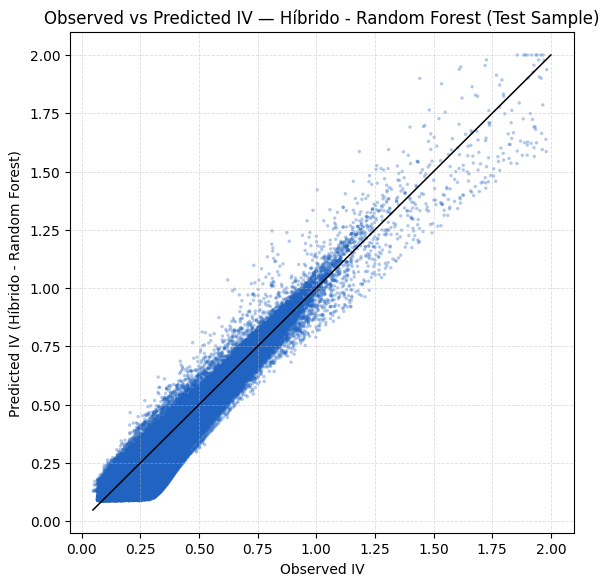

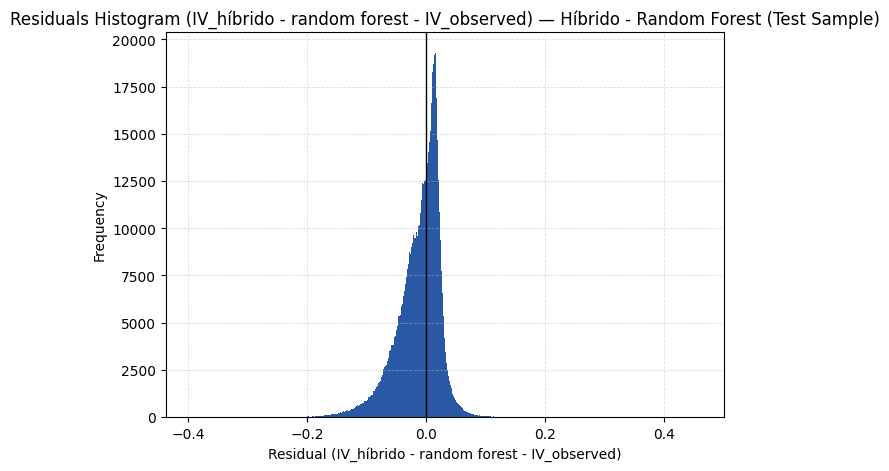

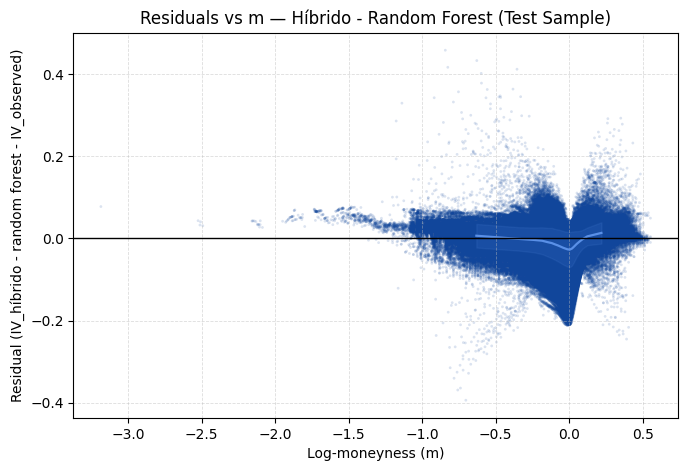

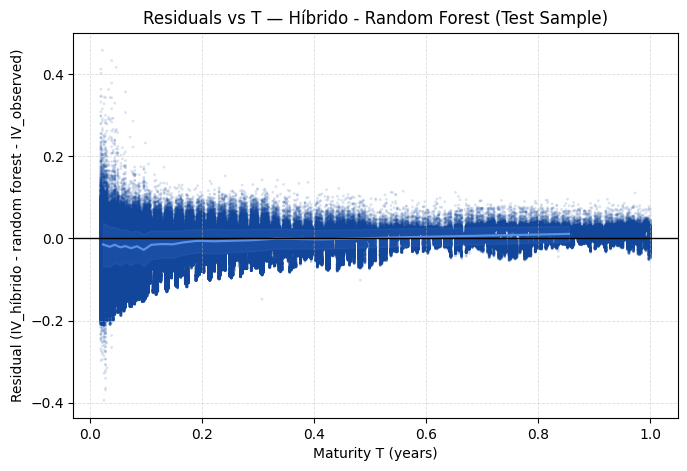

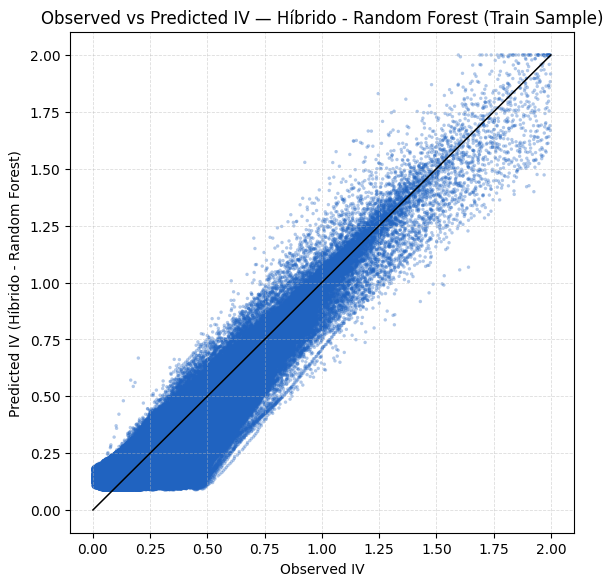

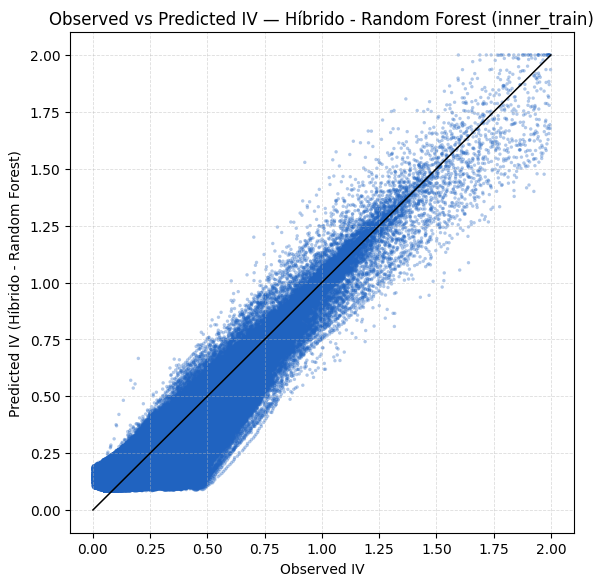

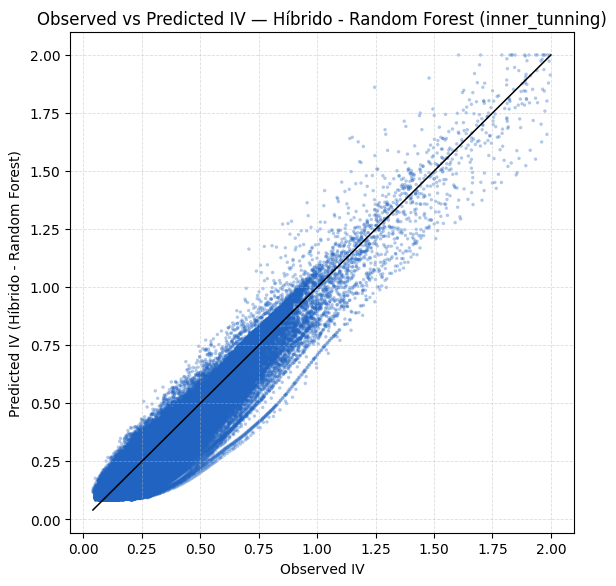

,model,split,analysis,variant,n_obs,RMSE,MAE,MedAE,R2,Bias
0,Híbrido - Random Forest,test_puro,geral,train_full,1292514,0.038328,0.027465,0.019243,0.891770,-1.129860e-02
1,Híbrido - Random Forest,train_full,especifica,train_full,7505238,0.042096,0.028780,0.021325,0.886394,2.973052e-07
2,Híbrido - Random Forest,Test Sample,geral,train_full,1292514,0.038328,0.027465,0.019243,0.891770,-1.129860e-02
3,Híbrido - Random Forest,Train Sample,especifica,train_full,7505238,0.042096,0.028780,0.021325,0.886394,2.973052e-07
4,Híbrido - Random Forest,inner_train,especifica,inner_training,5970843,0.044012,0.030061,0.021997,0.875331,7.297942e-07
5,Híbrido - Random Forest,inner_tunning,especifica,inner_training,1534395,0.034093,0.025187,0.020927,0.925987,4.748008e-03


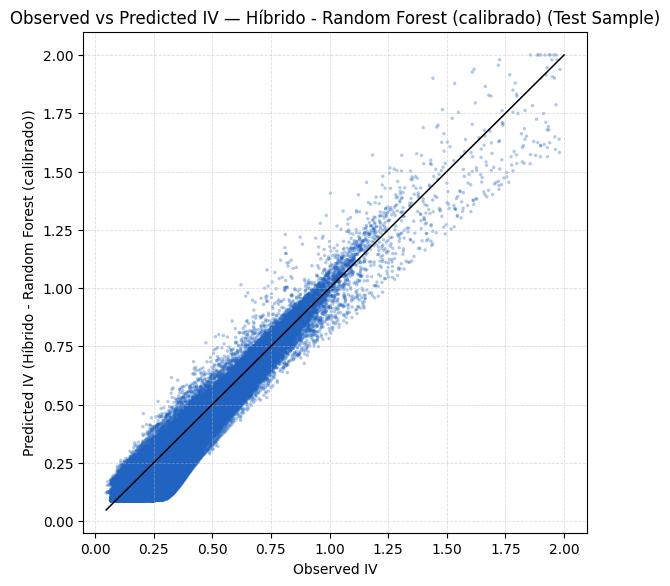

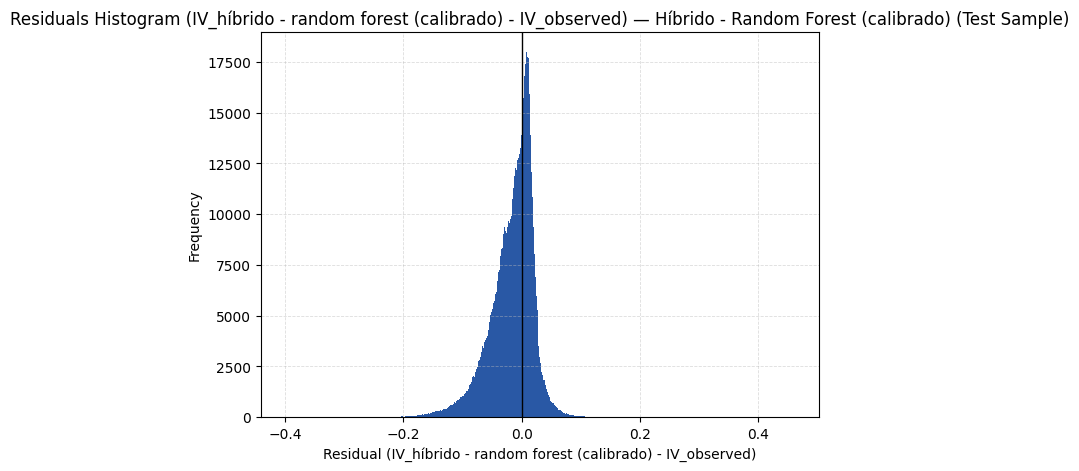

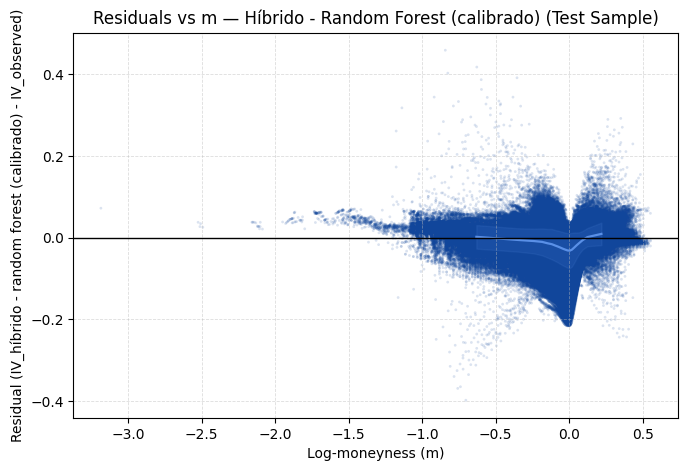

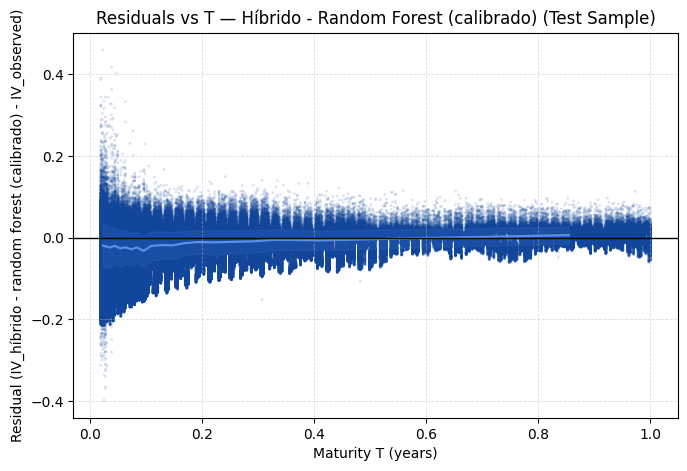

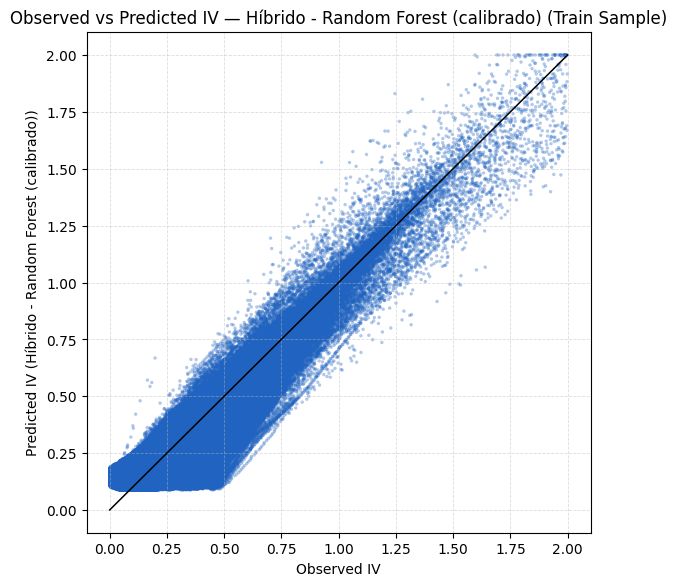

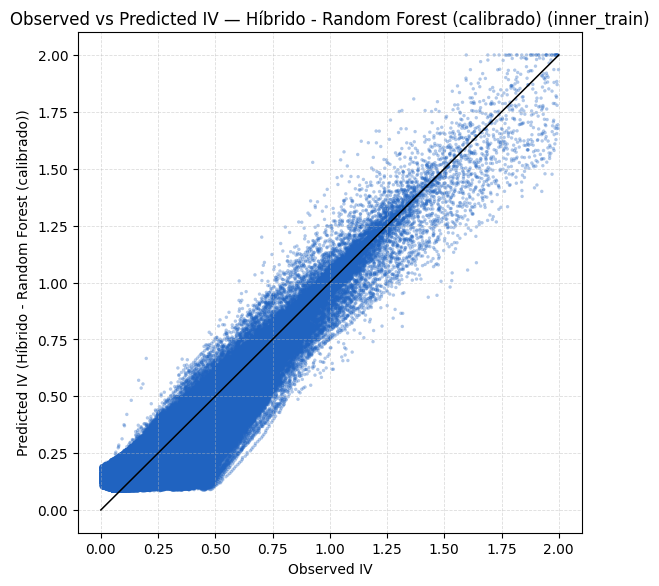

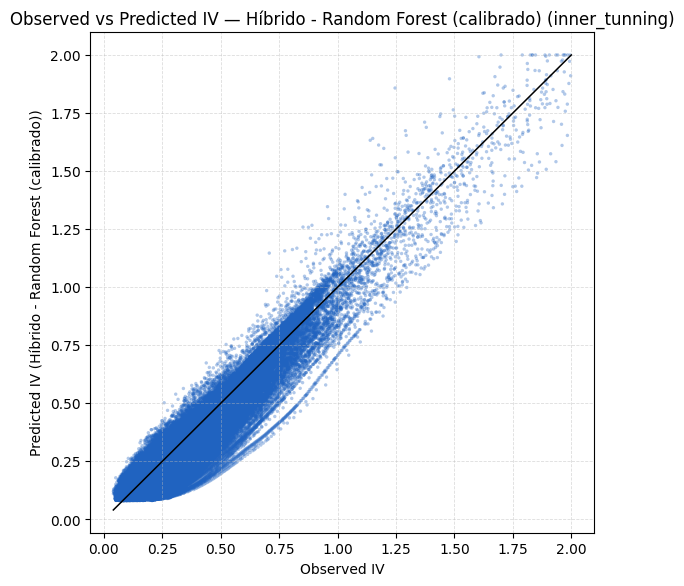

,model,split,analysis,variant,n_obs,RMSE,MAE,MedAE,R2,Bias
0,Híbrido - Random Forest (calibrado),test_puro,geral,train_full,1292514,0.040095,0.028374,0.018978,0.881561,-1.584609e-02
1,Híbrido - Random Forest (calibrado),train_full,especifica,train_full,7505238,0.042096,0.028780,0.021325,0.886394,2.973052e-07
2,Híbrido - Random Forest (calibrado),Test Sample,geral,train_full,1292514,0.040095,0.028374,0.018978,0.881561,-1.584609e-02
3,Híbrido - Random Forest (calibrado),Train Sample,especifica,train_full,7505238,0.042096,0.028780,0.021325,0.886394,2.973052e-07
4,Híbrido - Random Forest (calibrado),inner_train,especifica,inner_training,5970843,0.044012,0.030061,0.021997,0.875331,7.297942e-07
5,Híbrido - Random Forest (calibrado),inner_tunning,especifica,inner_training,1534395,0.033674,0.023925,0.018607,0.927796,-1.170920e-06


,model,split,analysis,variant,n_obs,RMSE,MAE,MedAE,R2,Bias
0,Híbrido - Random Forest (calibrado),test_puro,geral,train_full,1292514,0.040095,0.028374,0.018978,0.881561,-1.584609e-02
1,Híbrido - Random Forest (calibrado),train_full,especifica,train_full,7505238,0.042096,0.028780,0.021325,0.886394,2.973052e-07
2,Híbrido - Random Forest (calibrado),Test Sample,geral,train_full,1292514,0.040095,0.028374,0.018978,0.881561,-1.584609e-02
3,Híbrido - Random Forest (calibrado),Train Sample,especifica,train_full,7505238,0.042096,0.028780,0.021325,0.886394,2.973052e-07
4,Híbrido - Random Forest (calibrado),inner_train,especifica,inner_training,5970843,0.044012,0.030061,0.021997,0.875331,7.297942e-07


In [14]:
# --- 1) Run evaluation for uncalibrated model ---
res_rf = run_avaliacoes(
    df_inner_train=df_inner_train_pred,   # contém ivs_modelo
    df_inner_tunning=df_inner_tunning_pred,
    df_train_full=df_train_full_pred,
    df_test_puro=df_test_puro_pred,
    model="Híbrido - Random Forest",
    DIR_TABELAS=DIR_TABELAS,
    DIR_GRAFICOS=DIR_GRAFICOS,
    scatter_mode="all",
    max_points_scatter=250_000,
    dpi=160,
    display_in_notebook=True
)

res_rf["globais_df"].head()

# --- 2) Run evaluation for calibrated model ---
res_rf = run_avaliacoes(
    df_inner_train=df_inner_train_pred,   # contém ivs_modelo
    df_inner_tunning=df_inner_tunning_pred_cal,
    df_train_full=df_train_full_pred,
    df_test_puro=df_test_puro_pred_cal,
    model="Híbrido - Random Forest (calibrado)",
    DIR_TABELAS=DIR_TABELAS,
    DIR_GRAFICOS=DIR_GRAFICOS,
    scatter_mode="all",
    max_points_scatter=250_000,
    dpi=160,
    display_in_notebook=True
)

res_rf["globais_df"].head()

### 11. 3D Volatility Surface & Residual Diagnostics


IVS Teórica:


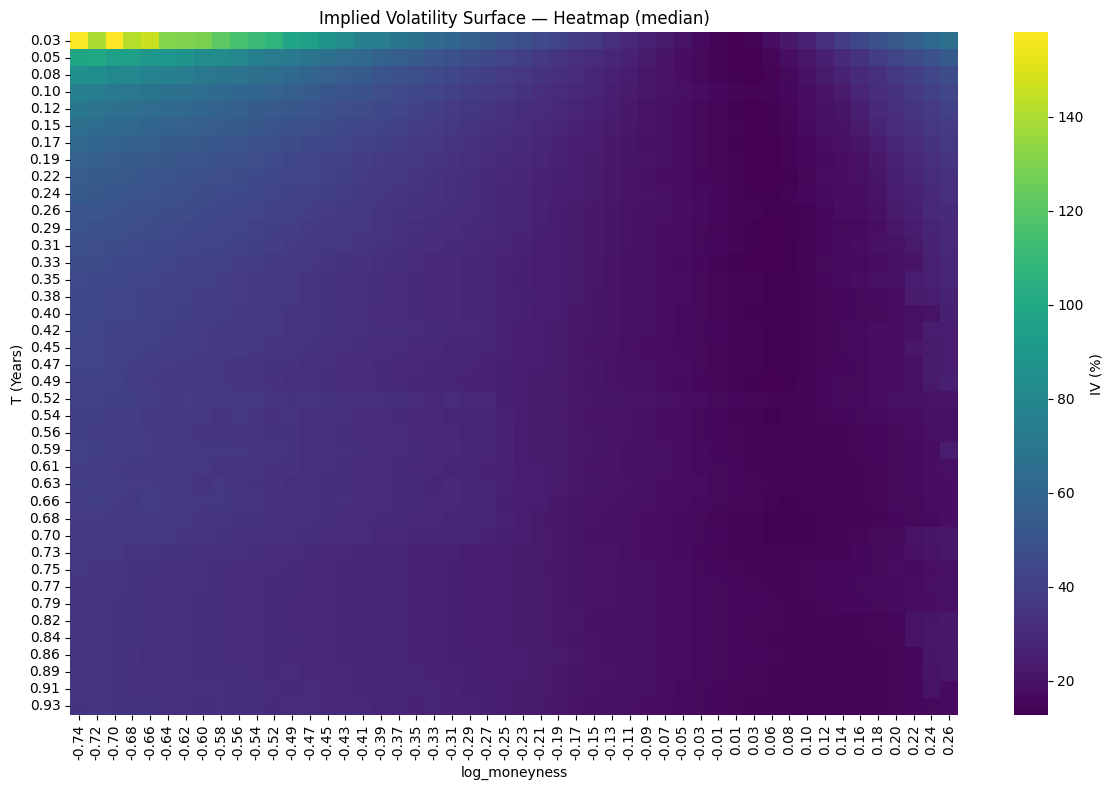

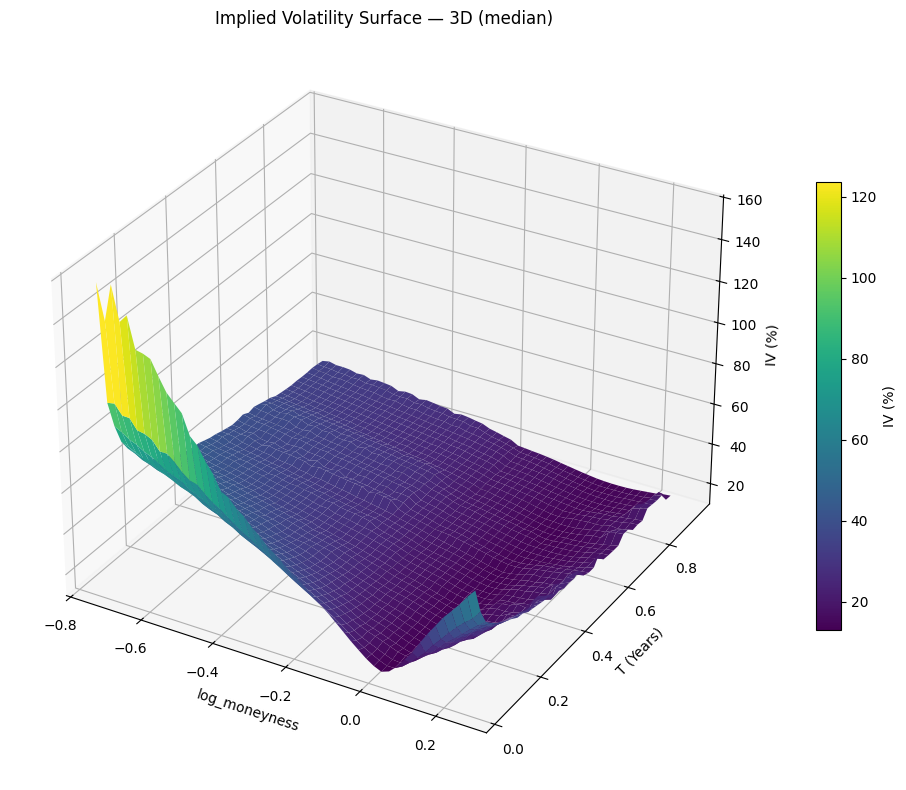

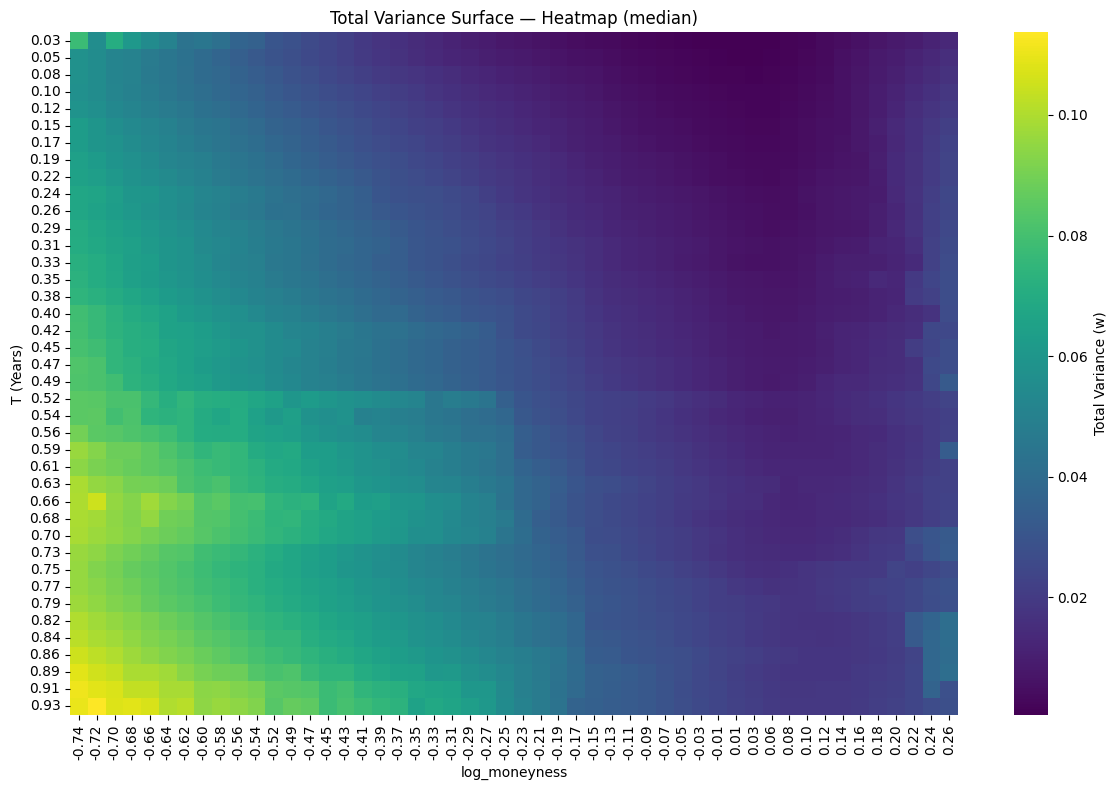

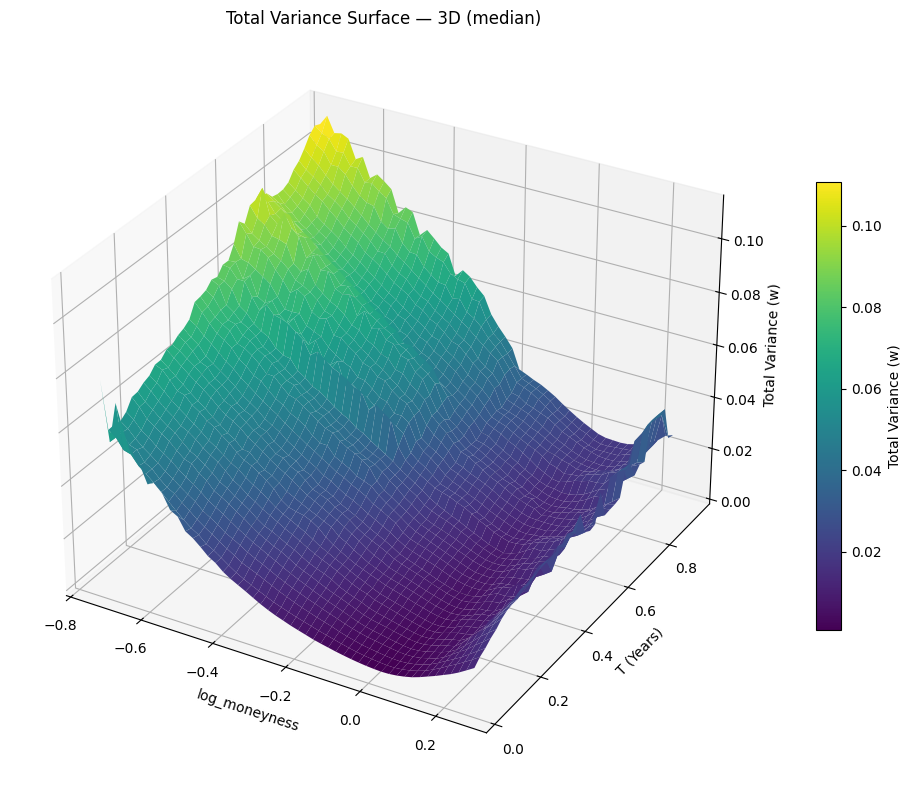

IVS Modelo (não calibrada):


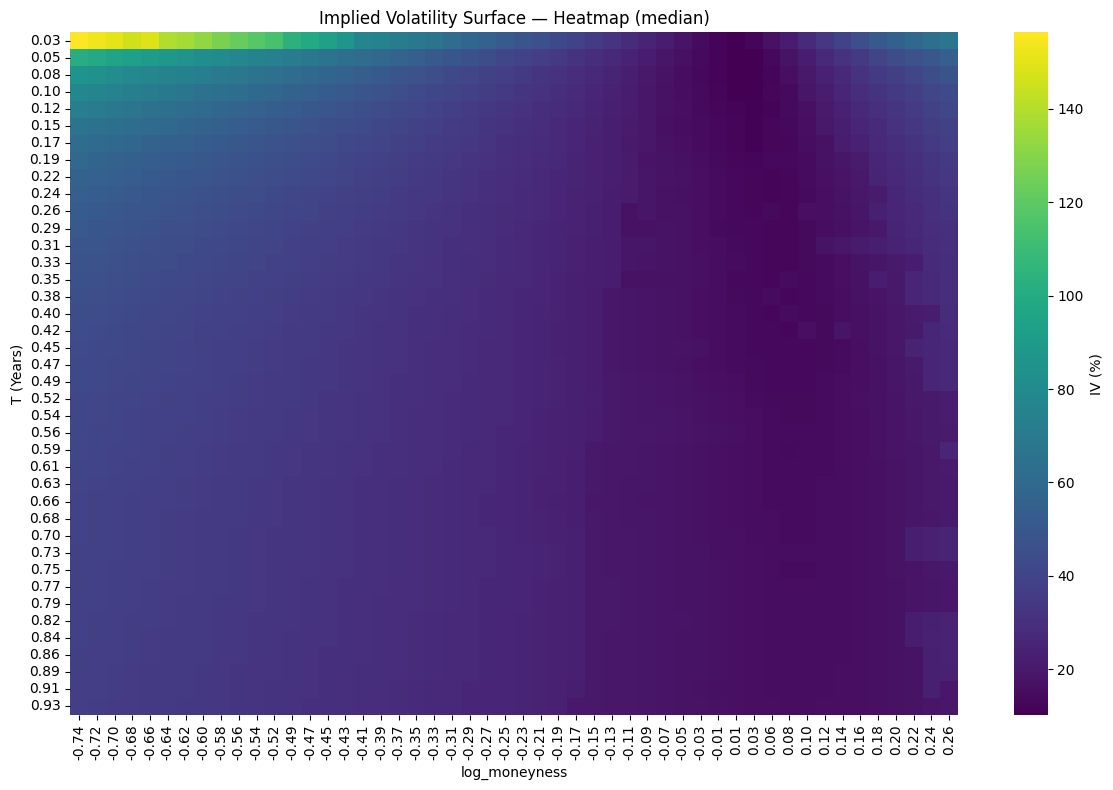

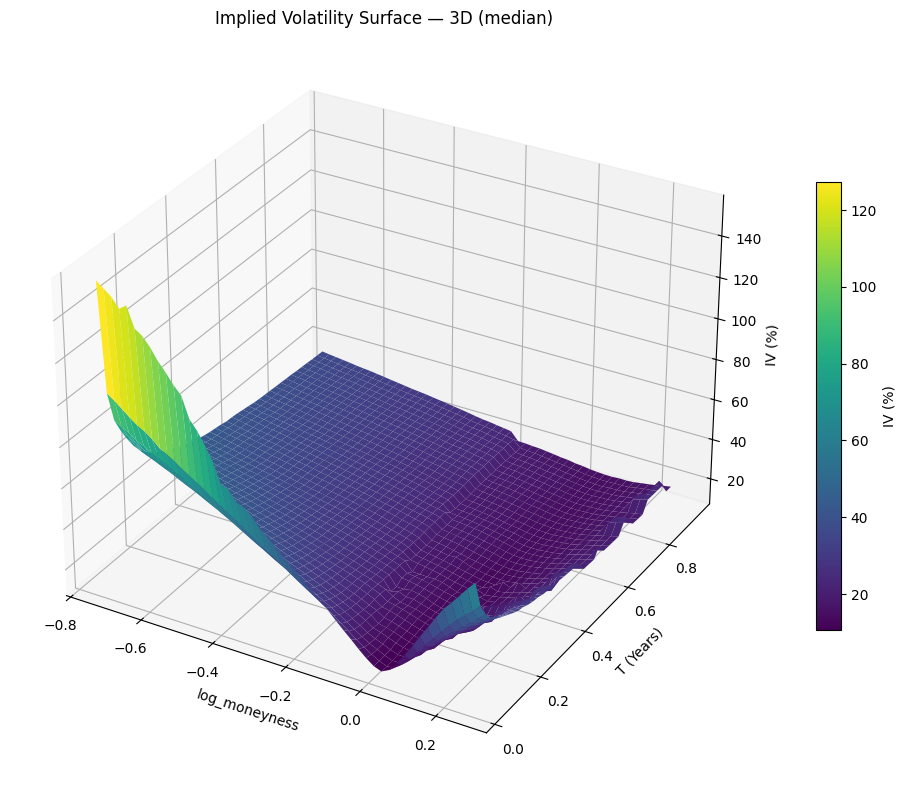

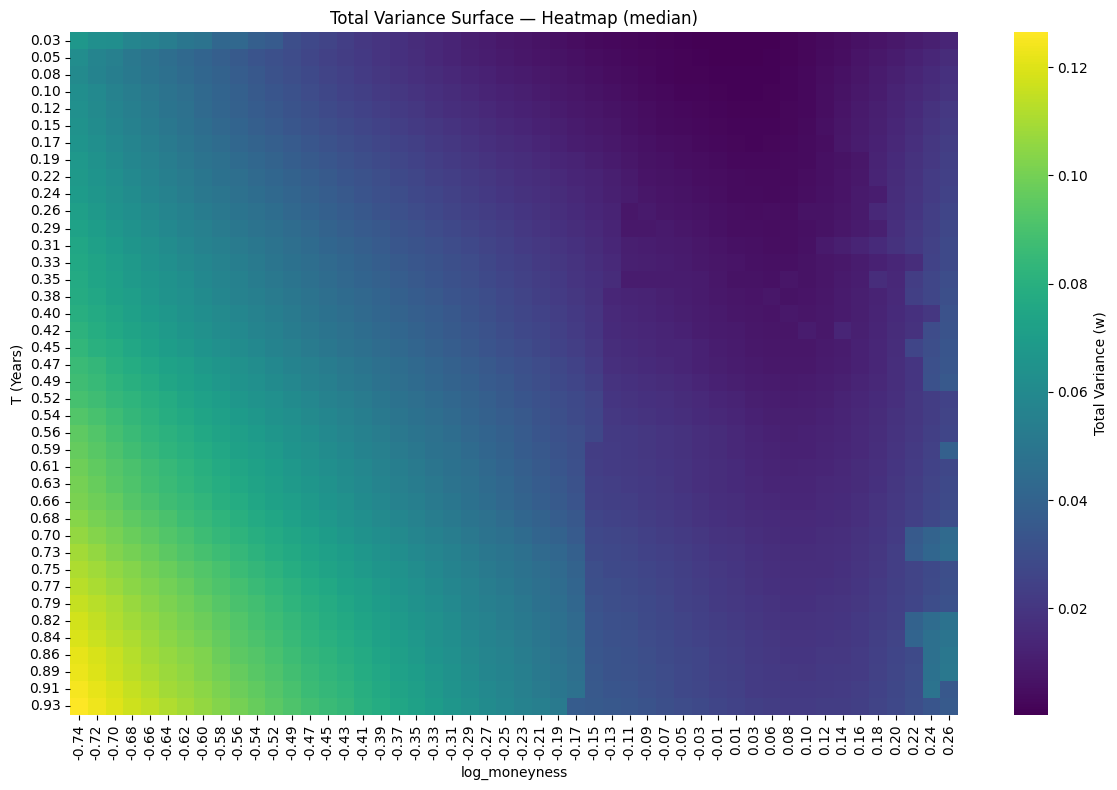

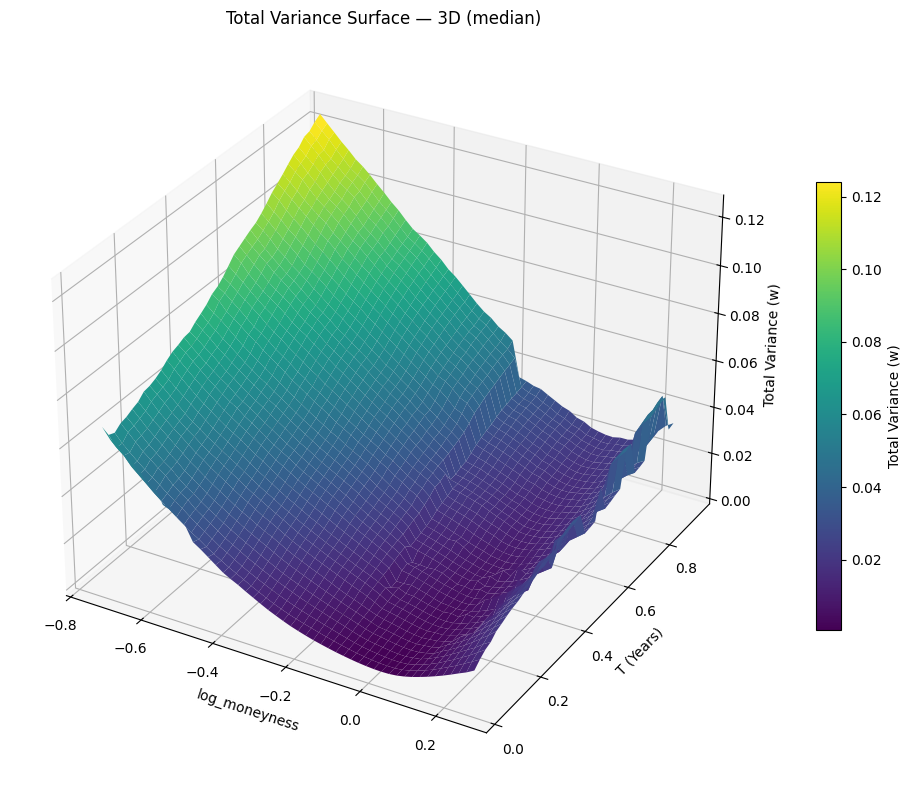

IVS Modelo (calibrada):


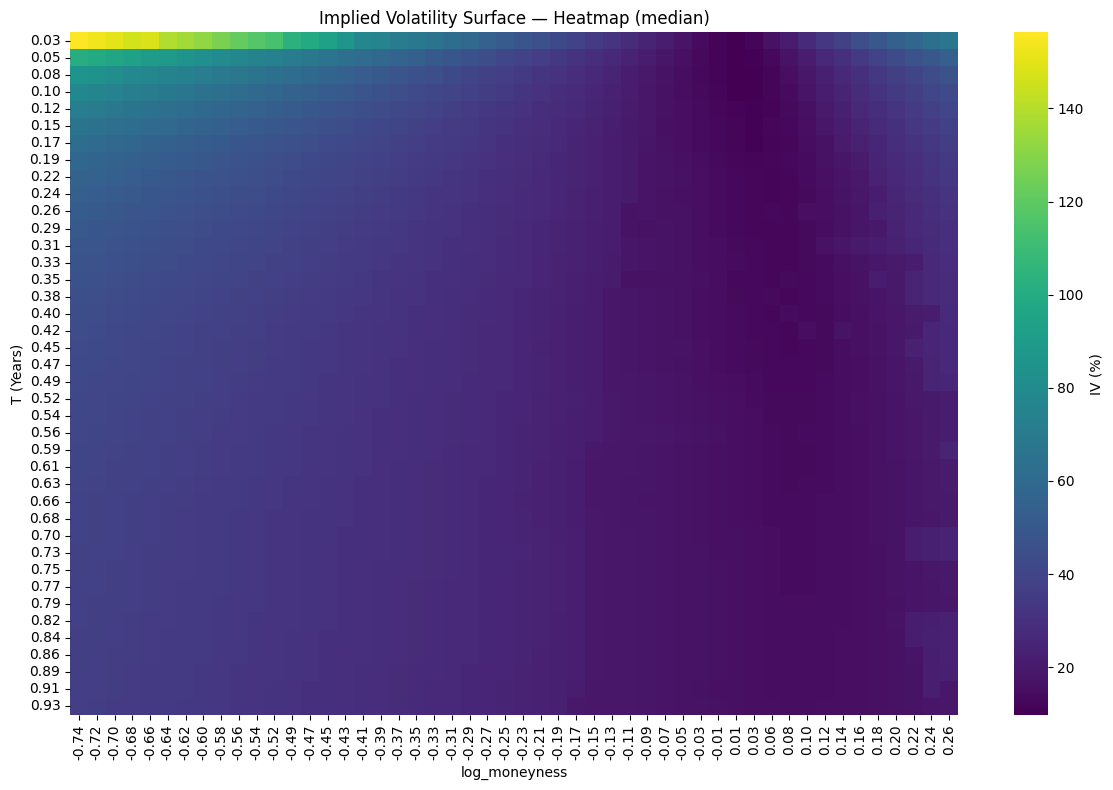

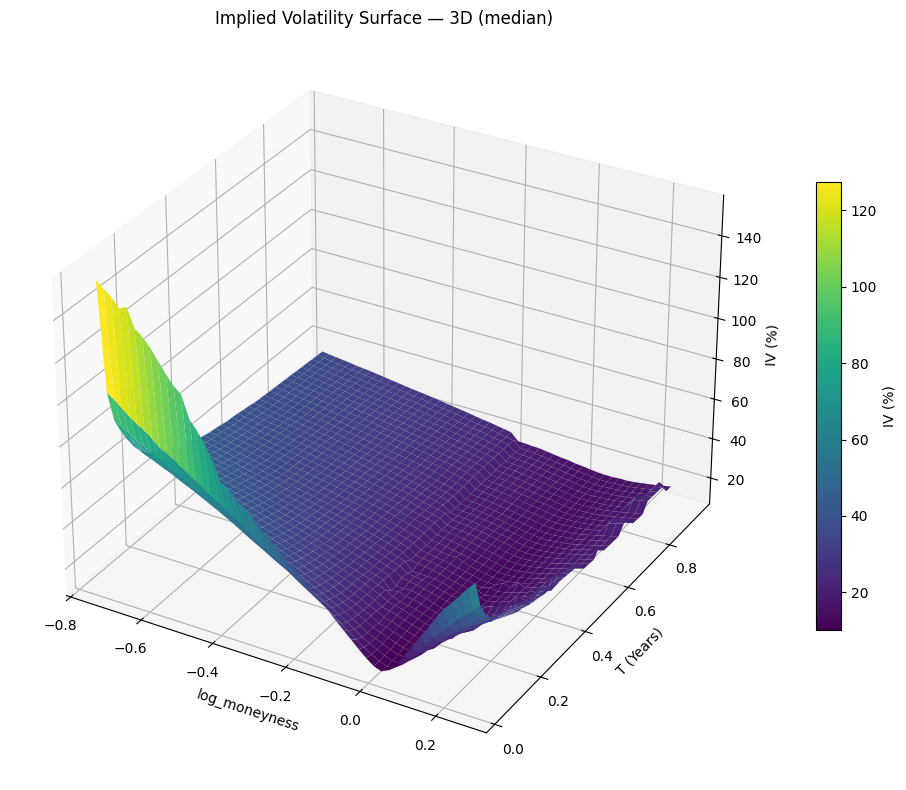

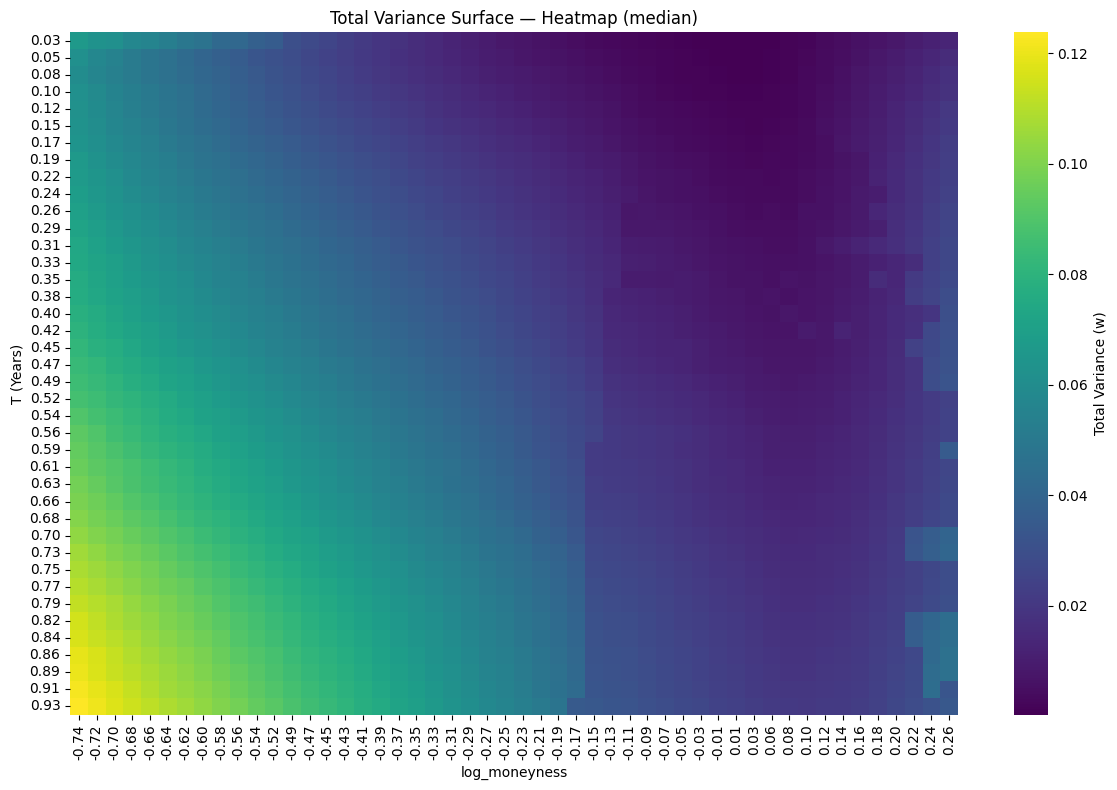

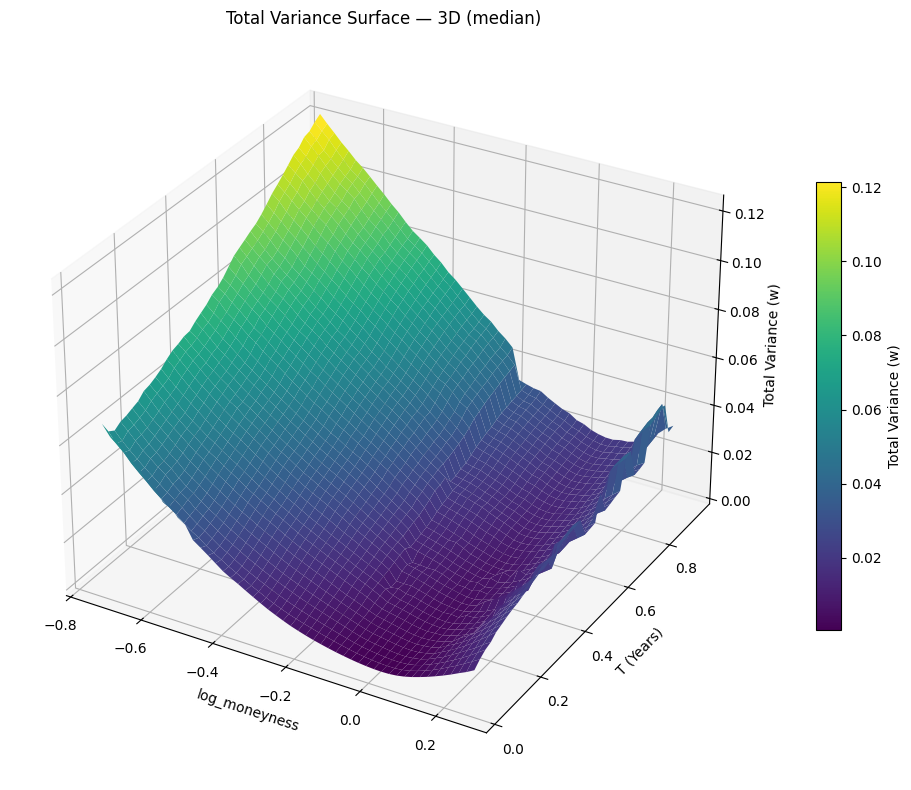

In [16]:
# 1) Superfície teórica
print("IVS Teórica:")
plot_ivs_and_variance_surfaces(
    df_test_puro_pred,
    x_col="log_moneyness", y_col="T", z_col="iv_teorica",
    agg="median",
    nbins_x=50, nbins_y=40,
    save_dir=DIR_GRAFICOS, filename_prefix="Random Forest"
)

# 2) Superfície de volatilidade implícita do modelo (não calibrada)
print("IVS Modelo (não calibrada):")
plot_ivs_and_variance_surfaces(
    df_test_puro_pred,
    x_col="log_moneyness", y_col="T", z_col="ivs_modelo",
    agg="median",
    nbins_x=50, nbins_y=40,
    save_dir=DIR_GRAFICOS, filename_prefix="Random Forest"

)

# 3) Superfície de volatilidade implícita do modelo (calibrada)
print("IVS Modelo (calibrada):")
plot_ivs_and_variance_surfaces(
    df_test_puro_pred_cal,
    x_col="log_moneyness", y_col="T", z_col="ivs_modelo",
    agg="median",
    nbins_x=50, nbins_y=40,
    save_dir=DIR_GRAFICOS, filename_prefix="Random Forest (calibrado)"
)